# Лабораторная работа №7. Эмбеддинги, чанки и метрики расстояний


In [ ]:
import os

if not (os.path.exists('documents.csv') and os.path.exists('chunks_embeddings.csv')):
    import numpy as np
    import pandas as pd

    np.random.seed(42)

    docs = [
        {'doc_id': 1, 'title': 'Введение в машинное обучение',
         'text': ('Машинное обучение — это область искусственного интеллекта, которая изучает методы построения моделей, '
                  'способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, '
                  'в машинном обучении правила выводятся из данных автоматически. Основные типы задач: классификация, '
                  'регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. '
                  'Регрессия предсказывает число, например, цену квартиры. Кластеризация разбивает объекты на группы '
                  'похожих. Обучение делится на обучение с учителем и без учителя. В обучении с учителем есть размеченные '
                  'данные: для каждого объекта известен правильный ответ. В обучении без учителя разметки нет, модель '
                  'сама находит структуру. Качество модели проверяют на отложенной выборке — тесте. Основные метрики '
                  'классификации: accuracy, precision, recall, F1. Для регрессии: MAE, RMSE. Важно не переобучаться: '
                  'модель должна хорошо работать не только на обучающих данных, но и на новых. Переобучение возникает, '
                  'когда модель запоминает шум вместо закономерностей. Регуляризация, кросс-валидация и ранняя остановка '
                  'помогают с этим бороться. Популярные библиотеки: scikit-learn, XGBoost, LightGBM, PyTorch.')},
        {'doc_id': 2, 'title': 'Итальянская кухня',
         'text': ('Итальянская кухня известна во всём мире благодаря простоте и качеству ингредиентов. Основные продукты — '
                  'оливковое масло, томаты, базилик, пармезан, чеснок. Паста — один из символов итальянской кухни. '
                  'Спагетти, пенне, фарфалле, ригатони — сотни форм, у каждой своё назначение. Соусы подбираются под форму '
                  'пасты: густые к короткой, жидкие к длинной. Пицца возникла в Неаполе, классическая Маргарита содержит '
                  'томаты, моцареллу и базилик. Тесто для пиццы должно выстаиваться не менее суток. Рижотто готовят из '
                  'риса арборио, постепенно добавляя бульон. Лазанья — слои теста, мясного соуса и бешамели. Тирамису '
                  'состоит из савоярди, кофе, маскарпоне и какао. Итальянцы пьют эспрессо стоя у барной стойки, '
                  'капучино — только утром. Сыры: пармезан, горгонзола, пекорино, моцарелла. Вина: кьянти, бароло, '
                  'просекко. Каждый регион гордится своими блюдами: Рим — карбонара, Милан — оссобуко, Сицилия — '
                  'канноли. Приём пищи в Италии — это ритуал, а не просто еда.')},
        {'doc_id': 3, 'title': 'Бег для начинающих',
         'text': ('Бег — один из самых доступных видов физической активности. Для начала достаточно кроссовок и '
                  'желания. Первые тренировки должны быть короткими: 15-20 минут в лёгком темпе. Главное правило — '
                  'не гнаться за скоростью. Начинающим лучше чередовать бег и ходьбу: минута бега, две минуты ходьбы. '
                  'Постепенно время бега увеличивается. Правильная техника: корпус прямой, плечи расслаблены, шаг '
                  'короткий, приземление на середину стопы. Дыхание должно быть ровным и глубоким. Разминка перед '
                  'бегом и растяжка после — обязательны. Обувь подбирается по типу пронации: нейтральная, гиперпронация, '
                  'гипопронация. Нельзя увеличивать объём больше, чем на 10 процентов в неделю. При болях в коленях, '
                  'спине или стопах необходимо обратиться к врачу. Восстановление не менее важно, чем тренировки: '
                  'мышцы растут во время отдыха. Питьевой режим: 200-300 мл воды за 30 минут до бега и столько же '
                  'после. Цель первых месяцев — привычка, а не результат.')},
        {'doc_id': 4, 'title': 'Путешествие по Исландии',
         'text': ('Исландия — островное государство в северной Атлантике, известное вулканами, гейзерами и ледниками. '
                  'Столица — Рейкьявик, самый северный в мире. Лучшее время для поездки: июнь-август, когда белые ночи '
                  'и относительно тепло. Зимой можно увидеть северное сияние, но погода суровая. Основные '
                  'достопримечательности: золотое кольцо (Тингветлир, Гейсир, Гюдльфосс), ледниковая лагуна '
                  'Йёкюльсаурлоун, чёрный пляж Рейнисфьяра, водопад Сельяландсфосс. Аренда автомобиля — самый удобный '
                  'способ передвижения. Дороги с буквой F в названии — горные, только для 4x4. Погода меняется '
                  'мгновенно: за день может быть солнце, дождь, ветер и снег. Одежда: несколько слоёв, непромокаемая '
                  'куртка, треккинговая обувь. Цены высокие, особенно на еду и бензин. Кухня: рыба, баранина, '
                  'скайр — местный йогурт. Исландцы верят в эльфов, к этому относятся с уважением. Купание в '
                  'геотермальных бассейнах — обязательная часть любой поездки. Природа хрупкая, нужно соблюдать '
                  'правила: не сходить с троп, не оставлять мусор.')},
        {'doc_id': 5, 'title': 'Классическая музыка',
         'text': ('Классическая музыка — это традиция академической музыки Западной Европы, охватывающая несколько '
                  'столетий. Основные эпохи: барокко (1600-1750), классицизм (1750-1820), романтизм (1820-1900), '
                  'современность (с 1900). В эпоху барокко творили Бах, Вивальди, Гендель. Их музыка полифонична, '
                  'основана на контрапункте. Классицизм — Моцарт, Гайдн, Бетховен. Здесь важны форма и ясность: '
                  'соната, симфония, квартет. Романтизм — Шопен, Лист, Вагнер, Чайковский. Музыка становится более '
                  'эмоциональной, гармония — свободнее. Основные жанры: симфония, концерт, соната, опера, балет, '
                  'квартет. Инструменты: скрипка, виолончель, фортепиано, оркестр. Дирижёр управляет оркестром жестами. '
                  'Партитура — нотная запись всех партий. Классическая музыка часто звучит в филармониях и оперных '
                  'театрах. В XX веке появились авангард, минимализм, электроакустика. Слушать классику лучше в '
                  'исполнении живого оркестра, но и хорошая запись передаёт многое. Главное — не торопиться: '
                  'симфония требует времени и внимания.')},
    ]

    for d in docs:
        d['text'] = d['text'][:3000]

    pd.DataFrame(docs).to_csv('documents.csv', index=False, encoding='utf-8')

    centers = {
        1: np.array([2.0, 1.5, 1.0, 0.5, 0.0, -0.5, -1.0, -1.5]),
        2: np.array([1.5, -0.5, 2.0, -1.0, 0.5, 1.0, -2.0, 0.0]),
        3: np.array([-1.5, 2.0, -0.5, 1.0, -2.0, 0.5, 1.0, -1.0]),
        4: np.array([0.5, -2.0, 1.0, -1.5, 2.0, -0.5, 0.0, 1.5]),
        5: np.array([-2.0, 0.0, -1.5, 2.0, -0.5, 1.5, -1.0, 0.5]),
    }

    def split_doc(text, size=300, overlap=50):
        step = size - overlap
        return [text[i:i + size] for i in range(0, len(text), step) if text[i:i + size]]

    rows, cid = [], 1
    for d in docs:
        for idx, chunk in enumerate(split_doc(d['text'])):
            emb = centers[d['doc_id']] + np.random.normal(0, 0.4, size=8)
            rows.append({
                'chunk_id': cid, 'doc_id': d['doc_id'], 'chunk_index': idx,
                'chunk_text': chunk,
                **{f'e{i + 1}': round(emb[i], 4) for i in range(8)},
                'topic': d['doc_id'] - 1,
            })
            cid += 1

    pd.DataFrame(rows).to_csv('chunks_embeddings.csv', index=False, encoding='utf-8')
    print('documents.csv и chunks_embeddings.csv созданы')
else:
    print('Файлы documents.csv и chunks_embeddings.csv уже существуют — генерация пропущена')



documents.csv и chunks_embeddings.csv созданы


## Подготовка данных

Если файлов `documents.csv` и `chunks_embeddings.csv` нет в папке — генерируем их кодом из задания (Lab-07.md). Код восстановлен из текста задания (в задании он был разбит переносами строк).

Если файлы уже есть — генерация пропускается.


In [ ]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import cosine, euclidean, cityblock, cdist
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Загрузка данных (если не читается в utf-8 — пробуем cp1251)
try:
    docs = pd.read_csv('documents.csv')
    chunks = pd.read_csv('chunks_embeddings.csv')
except UnicodeDecodeError:
    docs = pd.read_csv('documents.csv', encoding='cp1251')
    chunks = pd.read_csv('chunks_embeddings.csv', encoding='cp1251')

print('docs:', docs.shape, '| chunks:', chunks.shape)
print('В data-сетке topic = doc_id - 1, т.е. у каждого документа свой уникальный topic.')
chunks.head()


docs: (5, 3) | chunks: (21, 13)
В data-сетке topic = doc_id - 1, т.е. у каждого документа свой уникальный topic.


,chunk_id,doc_id,chunk_index,chunk_text,e1,e2,e3,e4,e5,e6,e7,e8,topic
0,1,1,0,Машинное обучение — это область искусственного...,2.1987,1.4447,1.2591,1.1092,-0.0937,-0.5937,-0.3683,-1.1930,0
1,2,1,1,ных автоматически. Основные типы задач: класси...,1.8122,1.7170,0.8146,0.3137,0.0968,-1.2653,-1.6900,-1.7249,0
2,3,1,2,жих. Обучение делится на обучение с учителем и...,1.5949,1.6257,0.6368,-0.0649,0.5863,-0.5903,-0.9730,-2.0699,0
3,4,1,3,отложенной выборке — тесте. Основные метрики ...,1.7822,1.5444,0.5396,0.6503,-0.2403,-0.6167,-1.2407,-0.7591,0
4,5,1,4,модель запоминает шум вместо закономерностей. ...,1.9946,1.0769,1.3290,0.0117,0.0835,-1.2839,-1.5313,-1.4213,0


## Задание 1. Готовые чанки

Число чанков на документ:
doc_id
1    5
2    4
3    4
4    4
5    4

Статистика длины чанков (в словах):
count    21.000000
mean     38.095238
std       6.187930
min      20.000000
25%      36.000000
50%      39.000000
75%      42.000000
max      48.000000


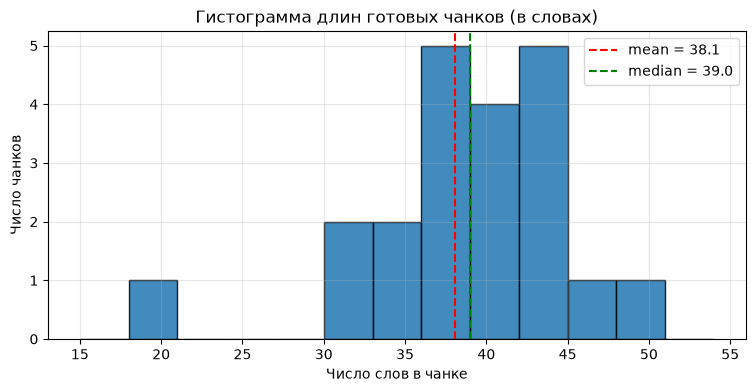

min = 20, max = 48, mean = 38.10, median = 39


In [ ]:
# Число слов в чанке
chunks['n_words'] = chunks['chunk_text'].str.split().str.len()

# Таблица документ -> число чанков
chunk_counts = chunks.groupby('doc_id').size().rename('n_chunks')
print('Число чанков на документ:')
print(chunk_counts.to_string())

# Статистика длин
desc = chunks['n_words'].describe()
print('\nСтатистика длины чанков (в словах):')
print(desc.to_string())

# Гистограмма
plt.figure(figsize=(9, 4))
chunks['n_words'].hist(bins=range(15, 55, 3), edgecolor='black', alpha=0.85)
plt.axvline(chunks['n_words'].mean(), color='red', linestyle='--',
            label=f"mean = {chunks['n_words'].mean():.1f}")
plt.axvline(chunks['n_words'].median(), color='green', linestyle='--',
            label=f"median = {chunks['n_words'].median():.1f}")
plt.xlabel('Число слов в чанке')
plt.ylabel('Число чанков')
plt.title('Гистограмма длин готовых чанков (в словах)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"min = {desc['min']:.0f}, max = {desc['max']:.0f}, "
      f"mean = {desc['mean']:.2f}, median = {chunks['n_words'].median():.0f}")


### Вывод по заданию 1

Всего 21 чанк. Длина в словах: min = 20, max = 48, mean = 38.1, median = 39. Гистограмма сосредоточена в диапазоне 35–45 слов, разброс небольшой (std == 6.2). В символах почти все чанки имеют длину ровно 300 (кроме последних чанков документов, где текст закончился раньше - минимальная длина 172 символа).

Почему чанки должны быть примерно одного размера? Во-первых, эмбеддинг - это вектор фиксированной размерности, и если чанки сильно различаются по объёму текста, один и тот же вектор «кодирует» разное количество информации, поэтому сравнивать расстояния между такими векторами некорректно. Во-вторых, одинаковая длина упрощает обработку, так как предсказуемое число чанков на документ, стабильный размер контекста для моделей, равномерная нагрузка на хранилище и поиск. В-третьих, при поиске по сходству важно, чтобы близость векторов отражала близость содержания, а не близость объёма текста.


## Задание 2. Разбиение документов тремя стратегиями

In [ ]:
def split_by_chars(text, size=300, overlap=0):
    step = size - overlap
    return [text[i:i + size] for i in range(0, len(text), step) if text[i:i + size]]


def split_by_sentences(text, min_group=2, max_group=3, min_len=150):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    sentences = [s for s in sentences if s.strip()]
    chunks_out, cur = [], []
    for s in sentences:
        cur.append(s)
        cur_len = len(' '.join(cur))
        if len(cur) >= max_group or (len(cur) >= min_group and cur_len >= min_len):
            chunks_out.append(' '.join(cur))
            cur = []
    if cur:
        chunks_out.append(' '.join(cur))
    return chunks_out


strategies = {
    '300 символов, без перекрытия': lambda t: split_by_chars(t, 300, 0),
    '300 символов, перекрытие 50': lambda t: split_by_chars(t, 300, 50),
    'по предложениям': split_by_sentences,
}

all_text = docs.set_index('doc_id')['text'].to_dict()

results = {}
for name, fn in strategies.items():
    per_doc = {d: fn(all_text[d]) for d in all_text}
    flat = [c for dd in per_doc.values() for c in dd]
    results[name] = per_doc
    lens = [len(c) for c in flat]
    words = [len(c.split()) for c in flat]
    print(f'=== {name} ===')
    print(f'  всего чанков: {len(flat)}, по документам: {[len(per_doc[d]) for d in sorted(per_doc)]}')
    print(f'  длина (симв.): mean = {np.mean(lens):.1f}, median = {np.median(lens):.1f}')
    print(f'  длина (слов):  mean = {np.mean(words):.1f}, median = {np.median(words):.1f}')
    print('  примеры:')
    for c in flat[:2]:
        print(f'    • {c[:95]}...')
    print()

# Сводная таблица
summary_rows = []
for name, per_doc in results.items():
    flat = [c for dd in per_doc.values() for c in dd]
    summary_rows.append({
        'стратегия': name,
        'число чанков': len(flat),
        'средняя длина, символов': round(np.mean([len(c) for c in flat]), 1),
        'медиана длины, символов': round(np.median([len(c) for c in flat]), 1),
        'средняя длина, слов': round(np.mean([len(c.split()) for c in flat]), 1),
    })
summary = pd.DataFrame(summary_rows)
summary

# Сравнение с готовыми чанками
ready = chunks.sort_values(['doc_id', 'chunk_index']).reset_index(drop=True)
flat_overlap = [c for d in sorted(all_text) for c in split_by_chars(all_text[d], 300, 50)]
match = ready['chunk_text'].iloc[:len(flat_overlap)].tolist() == flat_overlap
print('Готовые чанки == чанки «300 симв., перекрытие 50»:', match)
print('Длины готовых чанков (симв.):', sorted(chunks['chunk_text'].str.len().unique()))


=== 300 симв., без перекрытия ===
  всего чанков: 20, по документам: [4, 4, 4, 4, 4]
  длина (симв.): mean = 251.2, median = 300.0
  длина (слов):  mean = 34.5, median = 39.5
  примеры:
    • Машинное обучение — это область искусственного интеллекта, которая изучает методы построения мо...
    • ция, регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спа...

=== 300 симв., перекрытие 50 ===
  всего чанков: 21, по документам: [5, 4, 4, 4, 4]
  длина (симв.): mean = 277.3, median = 300.0
  длина (слов):  mean = 38.1, median = 39.0
  примеры:
    • Машинное обучение — это область искусственного интеллекта, которая изучает методы построения мо...
    • ных автоматически. Основные типы задач: классификация, регрессия, кластеризация. Классификация ...

=== по предложениям (2–3) ===
  всего чанков: 28, по документам: [6, 6, 5, 5, 6]
  длина (симв.): mean = 178.6, median = 184.0
  длина (слов):  mean = 24.2, median = 24.0
  примеры:
    • Машинное обучение —

### Вывод по заданию 2

**Сводная таблица стратегия -> число чанков, средняя длина:**

| стратегия | число чанков | средняя длина, симв. | медиана, симв. | среднее, слов |
|---|---|---|---|---|
| 300 симв., без перекрытия | 20 | 251.2 | 300 | 34.5 |
| 300 симв., перекрытие 50 | 21 | 277.3 | 300 | 38.1 |
| по предложениям (2–3) | 28 | 178.6 | 184.0 | 24.2 |

Примеры чанков для каждой стратегии выведены в ячейке выше, по два на стратегию.

Какая стратегия лучше? Для этих документов лучше всего подходит «300 символов с перекрытием 50»: перекрытие сохраняет контекст на границах чанков (смысловой кусок не теряется на стыке), а число чанков (21) минимально из «смысловых» вариантов. Без перекрытия чанков чуть меньше (20), но границы «разрезают» текст без учёта контекста. По предложениям получаются самые «смысловые» чанки (предложения не рвутся), но их больше (28) и они заметно короче и неравномернее.

Какая стратегия использована в готовых чанках? Стратегия «300 символов с перекрытием 50». Это видно по длинам готовых чанков (почти все ровно 300 символов, кроме последних чанков документов), а главное — все 21 готовый чанк побайтово совпадают с результатом этой стратегии. Ни одна другая стратегия не дала бы ровно 300-символьные чанки с таким же числом и содержанием.


## Задание 3. Метрики расстояний

In [ ]:
emb_cols = [f'e{i + 1}' for i in range(8)]
X = chunks[emb_cols].values

query = X[0]  # первый чанк doc_id == 1
print('Запрос: chunk_id =', chunks['chunk_id'].iloc[0],
      ', doc_id =', chunks['doc_id'].iloc[0],
      ', topic =', chunks['topic'].iloc[0])

cos_d = np.array([cosine(query, x) for x in X])
euc_d = np.array([euclidean(query, x) for x in X])
man_d = np.array([cityblock(query, x) for x in X])
dot_s = X @ query

metrics = pd.DataFrame({
    'chunk_id': chunks['chunk_id'],
    'doc_id': chunks['doc_id'],
    'cosine': cos_d,
    'euclid': euc_d,
    'manhattan': man_d,
    'dot': dot_s,
})

k = 5
tops = {
    'cosine': metrics.sort_values('cosine').head(k),
    'euclid': metrics.sort_values('euclid').head(k),
    'manhattan': metrics.sort_values('manhattan').head(k),
    'dot (по убыванию)': metrics.sort_values('dot', ascending=False).head(k),
}

for name, df in tops.items():
    print(f'--- Топ {k} по {name} ---')
    print(df[['chunk_id', 'doc_id', 'cosine', 'euclid', 'manhattan', 'dot']].to_string(index=False))
    print()

sets = {name: set(df['chunk_id']) for name, df in tops.items()}
print('Пересечения топ-5 (сколько общих чанков из 5):')
for n1 in sets:
    for n2 in sets:
        if n1 < n2:
            print(f'  {n1:16s} и {n2:14s}: {len(sets[n1] & sets[n2])}')

print()
print('Топ 5 по скалярному произведению по возрастанию: ')
print(metrics.sort_values('dot').head(k)[['chunk_id', 'doc_id', 'dot', 'cosine']].to_string(index=False))


Запрос: chunk_id = 1 , doc_id = 1 , topic = 0
--- Топ-5 по cosine ---
 chunk_id  doc_id   cosine   euclid  manhattan       dot
        1       1 0.000000 0.000000     0.0000 11.657251
        4       1 0.083139 1.372244     3.1705  9.301648
        2       1 0.131923 1.889729     4.6145 11.261024
        5       1 0.133041 1.816258     3.9980 10.641662
        3       1 0.162221 1.939106     4.7462  9.708435

--- Топ-5 по euclid ---
 chunk_id  doc_id   cosine   euclid  manhattan       dot
        1       1 0.000000 0.000000     0.0000 11.657251
        4       1 0.083139 1.372244     3.1705  9.301648
        5       1 0.133041 1.816258     3.9980 10.641662
        2       1 0.131923 1.889729     4.6145 11.261024
        3       1 0.162221 1.939106     4.7462  9.708435

--- Топ-5 по manhattan ---
 chunk_id  doc_id   cosine   euclid  manhattan       dot
        1       1 0.000000 0.000000     0.0000 11.657251
        4       1 0.083139 1.372244     3.1705  9.301648
        5       1 0.13

### Вывод по заданию 3

**Таблица чанк -> cosine / euclid / manhattan / dot для пяти ближайших соседей:**

| chunk_id | doc_id | cosine | euclid | manhattan | dot |
|---|---|---|---|---|---|
| 1 | 1 | 0.000 | 0.000 | 0.000 | 11.657 |
| 4 | 1 | 0.083 | 1.372 | 3.171 | 9.302 |
| 2 | 1 | 0.132 | 1.890 | 4.615 | 11.261 |
| 5 | 1 | 0.133 | 1.816 | 3.998 | 10.642 |
| 3 | 1 | 0.162 | 1.939 | 4.746 | 9.708 |

Топ 5 по всем четырём метрикам — одни и те же чанки (собственные чанки запроса из документа 1), но **внутренний порядок расходится: по косинусу [1, 4, 2, 5, 3], по евклиду и манхэттену [1, 4, 5, 2, 3], по dot [1, 2, 5, 3, 4]. Пересечения топ-5 — 5 из 5 у всех пар, т.е. наборы совпадают, а порядок нет. Причина расхождения: косинус игнорирует длину вектора, а евклид/манхэттен и dot её учитывают; у чанков разные нормы (например, у чанка 2 норма больше, чем у чанка 4, поэтому по dot он выше, хотя по направлению дальше).

Если отсортировать dot product по возрастанию, ближайшими становятся чанки с максимально отрицательным скалярным произведением: chunk 21 (doc 5, dot = −6.48), 18 (doc 5, −6.32), 20 (doc 5, −6.09), 19 (doc 5, −5.96), 17 (doc 4, −5.51). Это чанки документов 5 и 4, чьи центры почти противоположны центру документа 1 (cos(центр1, центр5) ≈ −0.40, cos(центр1, центр4) ≈ −0.30). То есть сортировка dot по возрастанию показывает противоположно похожие чанки, а не ближайшие.


## Задание 4. L2-нормализация


In [ ]:
norms = np.linalg.norm(X, axis=1)
X_norm = X / norms[:, None]

print('Длины после нормализации: min =', np.linalg.norm(X_norm, axis=1).min(),
      ', max =', np.linalg.norm(X_norm, axis=1).max())
print('Все векторы единичной длины:', np.allclose(np.linalg.norm(X_norm, axis=1), 1.0))

q_n = X_norm[0]
cos_n = np.array([cosine(q_n, x) for x in X_norm])
euc_n = np.array([euclidean(q_n, x) for x in X_norm])
man_n = np.array([cityblock(q_n, x) for x in X_norm])
dot_n = X_norm @ q_n

metrics_n = pd.DataFrame({
    'chunk_id': chunks['chunk_id'],
    'doc_id': chunks['doc_id'],
    'cosine': cos_n,
    'euclid': euc_n,
    'manhattan': man_n,
    'dot': dot_n,
})

tops_n = {
    'cosine': metrics_n.sort_values('cosine').head(k),
    'euclid': metrics_n.sort_values('euclid').head(k),
    'manhattan': metrics_n.sort_values('manhattan').head(k),
    'dot (по убыв.)': metrics_n.sort_values('dot', ascending=False).head(k),
}
for name, df in tops_n.items():
    print(f'--- Топ-{k} по {name} (L2-нормализованные) ---')
    print(df[['chunk_id', 'doc_id', 'cosine', 'euclid', 'manhattan', 'dot']].to_string(index=False))
    print()

order_cos = metrics_n.sort_values('cosine')['chunk_id'].values
order_dot = metrics_n.sort_values('dot', ascending=False)['chunk_id'].values
order_euc = metrics_n.sort_values('euclid')['chunk_id'].values
print('Порядок cosine == порядок dot (по убыв.):', np.array_equal(order_cos, order_dot))
print('Порядок cosine == порядок euclid:         ', np.array_equal(order_cos, order_euc))

a, b = X_norm[0], X_norm[1]
lhs = np.sum((a - b) ** 2)
rhs = 2 - 2 * np.dot(a, b)
print(f'Проверка формулы: ||a-b||^2 = {lhs:.6f}, 2 - 2*cos(a,b) = {rhs:.6f}, разница = {abs(lhs - rhs):.2e}')

scaler = StandardScaler()
X_z = scaler.fit_transform(X)
q_z = X_z[0]
cos_z = np.array([cosine(q_z, x) for x in X_z])

mz = pd.DataFrame({'chunk_id': chunks['chunk_id'], 'doc_id': chunks['doc_id'],
                   'cosine_raw': cos_d, 'cosine_z': cos_z})
top_raw = mz.sort_values('cosine_raw').head(k)['chunk_id'].tolist()
top_z = mz.sort_values('cosine_z').head(k)['chunk_id'].tolist()
print('Топ-5 по косинусу ДО Z-score:   ', top_raw)
print('Топ-5 по косинусу ПОСЛЕ Z-score:', top_z)
print('Топ-5 совпадают?', top_raw == top_z)

top10_raw = mz.sort_values('cosine_raw').head(10)['chunk_id'].tolist()
top10_z = mz.sort_values('cosine_z').head(10)['chunk_id'].tolist()
print('Топ-10 ДО Z-score:   ', top10_raw)
print('Топ-10 ПОСЛЕ Z-score:', top10_z)
print('Совпадение топ-10:', top10_raw == top10_z)


Длины после нормализации: min = 0.9999999999999998 , max = 1.0000000000000002
Все векторы единичной длины: True
--- Топ-5 по cosine (L2-нормализованные) ---
 chunk_id  doc_id   cosine   euclid  manhattan      dot
        1       1 0.000000 0.000000   0.000000 1.000000
        4       1 0.083139 0.407771   0.924712 0.916861
        2       1 0.131923 0.513659   1.246020 0.868077
        5       1 0.133041 0.515832   1.133165 0.866959
        3       1 0.162221 0.569598   1.394525 0.837779

--- Топ-5 по euclid (L2-нормализованные) ---
 chunk_id  doc_id   cosine   euclid  manhattan      dot
        1       1 0.000000 0.000000   0.000000 1.000000
        4       1 0.083139 0.407771   0.924712 0.916861
        2       1 0.131923 0.513659   1.246020 0.868077
        5       1 0.133041 0.515832   1.133165 0.866959
        3       1 0.162221 0.569598   1.394525 0.837779

--- Топ-5 по manhattan (L2-нормализованные) ---
 chunk_id  doc_id   cosine   euclid  manhattan      dot
        1       1 0.

### Вывод по заданию 4

После L2-нормализации все векторы имеют длину 1. Топ 5 по всем четырём метрикам совпадает по набору: {1, 4, 2, 5, 3}.

| метрика | топ 5 |
|---|---|
| cosine | 1, 4, 2, 5, 3 |
| euclid | 1, 4, 2, 5, 3 |
| manhattan | 1, 4, 5, 2, 3 |
| dot (по убыв.) | 1, 4, 2, 5, 3 |

- cosine и dot дают одинаковый порядок, потому что для единичных векторов, т.е. `cosine_distance = 1 − dot`, а монотонное преобразование `1 − x` порядок не меняет.
- euclidean отличается по абсолютным значениям (для пары (1, 4): euclid = 0.408, cosine = 0.083), но порядок совпадает, так как для единичных векторов - евклидово расстояние монотонно зависит от косинусного.
- manhattan даёт тот же набор топ-5, но внутри порядок чуть другой ([1, 4, 5, 2, 3]) - манхэттенское расстояние не связано с косинусом монотонно, поэтому строгого совпадения порядка не гарантирует.
- Формула подтверждена: для пары нормализованных векторов (1, 2) получили `0.263846` и `0.263846` .

Z-score (StandardScaler по столбцам): топ-5 по косинусу остался тем же ([1, 4, 2, 5, 3]) - собственные чанки запроса настолько ближе остальных, что масштабирование их не перемешивает. Но ранжирование дальше меняется: топ-10 после Z-score = [1, 4, 2, 5, 3, 12, 10, 13, 11, 9] против [1, 4, 2, 5, 3, 9, 8, 6, 7, 12] до него, а сами значения косинуса меняются сильно (например, для чанка 9: 0.555 → 0.987).

Почему Z-score меняет косинус, а L2-нормализация - нет? L2-нормализация - это умножение каждой строки на положительный скаляр `1/len(x)`: угол между векторами не меняется, поэтому косинус (и порядок соседей) сохраняется. Z-score - это аффинное преобразование по столбцам `x_j -> (x_j − mean_j) / std_j`: каждая компонента масштабируется и сдвигается по-своему, поэтому направления векторов меняются, а с ними меняются и углы, и косинусы. Косинусу все равно на масштабирование строк, но не на масштабирование столбцов.


## Задание 5. Поиск по чанкам

Для каждого чанка из doc_id=1 найдём три ближайших чанка из других документов (doc_id ≠ 1). Сделаем три варианта:

1. косинус на исходных векторах;
2. косинус на L2-нормализованных векторах;
3. дополнительно: евклидово расстояние на L2-нормализованных векторах (должно совпасть с косинусом).

Метрика качества — доля случаев, когда найденный сосед имеет тот же topic, что и запрос. Усредняем по всем чанкам из doc_id=1.


In [ ]:
from collections import Counter

q_pos = np.where(chunks['doc_id'] == 1)[0]
c_pos = np.where(chunks['doc_id'] != 1)[0]


def top_k_neighbors(Xmat, q_pos, c_pos, k=3, metric='cosine'):
    d = cdist(Xmat[q_pos], Xmat[c_pos], metric=metric)
    return np.argsort(d, axis=1)[:, :k]


def quality(nbrs, q_pos, c_pos):
    q_t = chunks['topic'].values[q_pos]
    c_t = chunks['topic'].values[c_pos]
    return np.mean([c_t[j] == q_t[i] for i, row in enumerate(nbrs) for j in row])


def doc_distribution(nbrs, c_pos):
    cnt = Counter()
    for row in nbrs:
        for j in row:
            cnt[int(chunks['doc_id'].values[c_pos[j]])] += 1
    return dict(sorted(cnt.items()))


variants = {
    'косинус (исходные)': top_k_neighbors(X, q_pos, c_pos, 3, 'cosine'),
    'косинус (L2-норм.)': top_k_neighbors(X_norm, q_pos, c_pos, 3, 'cosine'),
    'евклид (L2-норм.)': top_k_neighbors(X_norm, q_pos, c_pos, 3, 'euclidean'),
}

rows_q = []
for name, nbrs in variants.items():
    rows_q.append({'вариант': name,
                   'доля правильных соседей': round(quality(nbrs, q_pos, c_pos), 3),
                   'распределение соседей по doc_id': doc_distribution(nbrs, c_pos)})
print(pd.DataFrame(rows_q).to_string(index=False))

print('Примеры (косинус на исходных векторах):')
for i in range(3):
    qid = chunks['chunk_id'].values[q_pos[i]]
    nbrs = variants['косинус (исходные)'][i]
    nbr_ids = chunks['chunk_id'].values[c_pos[nbrs]]
    nbr_docs = chunks['doc_id'].values[c_pos[nbrs]]
    nbr_topics = chunks['topic'].values[c_pos[nbrs]]
    print(f'  запрос chunk {qid} (topic {chunks["topic"].values[q_pos[i]]}) → '
          f'соседи {list(nbr_ids)} (doc {list(nbr_docs)}, topic {list(nbr_topics)})')

same = all((variants['косинус (исходные)'] == v).all() for v in variants.values())
print('Все варианты дают одинаковый набор соседей:', same)


           вариант  доля правильных соседей распределение соседей по doc_id
косинус (исходные)                      0.0                         {2: 15}
косинус (L2-норм.)                      0.0                         {2: 15}
 евклид (L2-норм.)                      0.0                         {2: 15}

Примеры (косинус на исходных векторах):
  запрос chunk 1 (topic 0) → соседи [np.int64(9), np.int64(8), np.int64(6)] (doc [np.int64(2), np.int64(2), np.int64(2)], topic [np.int64(1), np.int64(1), np.int64(1)])
  запрос chunk 2 (topic 0) → соседи [np.int64(8), np.int64(9), np.int64(6)] (doc [np.int64(2), np.int64(2), np.int64(2)], topic [np.int64(1), np.int64(1), np.int64(1)])
  запрос chunk 3 (topic 0) → соседи [np.int64(8), np.int64(9), np.int64(6)] (doc [np.int64(2), np.int64(2), np.int64(2)], topic [np.int64(1), np.int64(1), np.int64(1)])

Все варианты дают одинаковый набор соседей: True


### Вывод по заданию 5

**Таблица вариант -> доля правильных соседей:**

| вариант | доля правильных соседей | распределение соседей по doc_id |
|---|---|---|
| косинус (исходные) | 0.000 | {2: 15} |
| косинус (L2-норм.) | 0.000 | {2: 15} |
| евклид (L2-норм.) | 0.000 | {2: 15} |

По определённой в задании метрике все три варианта дают 0.000. Причина — в устройстве датасета: `topic = doc_id − 1`, т.е. у каждого документа свой единственный topic. У запросов из doc_id=1 topic = 0, а у всех чанков из других документов topic ∈ {1, 2, 3, 4}, поэтому «тот же topic» невозможен в принципе. Метрика в таком виде вырождается для doc_id=1 и не различает варианты.

Содержательное сравнение даёт распределение соседей по документам: все 15 найденных соседей (5 запросов × 3 соседа) для всех вариантов — чанки doc_id=2. Это ожидаемо: центр документа 2 ближе всего к центру документа 1 (cos(центр1, центр2) ≈ 0.443, а с остальными центрами 0.020, −0.302, −0.403). Примеры для первых трёх чанков doc_id=1:

- chunk 1 (topic 0) → соседи 9, 8, 6 (doc 2, topic 1)
- chunk 2 (topic 0) → соседи 8, 9, 6 (doc 2, topic 1)
- chunk 3 (topic 0) → соседи 8, 9, 6 (doc 2, topic 1)

Все три варианта дают идентичные наборы соседей (`same = True`): косинус инвариантен к L2-нормализации (это масштабирование строк), а евклид на единичных векторах монотонно эквивалентен косинусному расстоянию. Поэтому лучший вариант выбрать нельзя, ведь они эквивалентны. 


## Задание 6. Выводы

Итоговые выводы по всей работе — на основе конкретных чисел из таблиц выше.


### Выводы по работе

1. Готовые чанки почти все имеют длину ровно 300 символов (38–48 слов); по 4 чанка на документы 2–5 и 5 на документ 1 — единый размер делает эмбеддинги сопоставимыми.
2. Сравнение стратегий: без перекрытия — 20 чанков (средняя длина 251 символов, с перекрытием 50 — 21 чанк (277 символов, по предложениям — 28 чанков (179 символов. Готовые чанки побайтово совпали со стратегией «300 символов с перекрытием 50», значит в данных использовалась именно она.
3. На исходных векторах топ 5 соседей по всем четырём метрикам — одни и те же чанки документа 1, но внутренний порядок расходится: косинус даёт [1, 4, 2, 5, 3], евклид и манхэттен — [1, 4, 5, 2, 3], dot — [1, 2, 5, 3, 4]. Причина — разные нормы векторов: косинус их игнорирует, а евклид и dot учитывают.
4. Сортировка dot product по возрастанию выводит на первые места чанки документов 5 и 4 (chunk 21 с dot ≈ −6.48) — это векторы, направленные почти противоположно запросу, т.е. противоположную похожесть, а не близость.
5. После L2-нормализации все метрики дали одинаковый набор топ 5 {1, 4, 2, 5, 3}, а порядок совпал у cosine, euclid и dot ([1, 4, 2, 5, 3]); манхэттен дал [1, 4, 5, 2, 3], так как он не связан с косинусом монотонно. 
6. Z-score (StandardScaler по столбцам) топ 5 не изменил, но переставил места 6–10 ранжирования (после Z-score: [1, 4, 2, 5, 3, 12, 10, 13, 11, 9] против [1, 4, 2, 5, 3, 9, 8, 6, 7, 12]) и сильно изменил значения косинуса — потому что масштабирование по столбцам меняет направления векторов, а косинус инвариантен только к масштабированию строк.
7. Поиск по чанкам doc_id=1: все варианты (косинус исходный, косинус L2, евклид L2) находят одни и те же три ближайших чанка из doc_id=2 — документа с ближайшим центром; заданная метрика «тот же topic» даёт 0.0, так как topic уникален для каждого документа.
8. Для реального проекта поиска я бы выбрал L2-нормализацию по строкам: она приводит все векторы к единичной длине, делает косинус и скалярное произведение эквивалентными, не искажает направления (в отличие от z-score) и позволяет сравнивать векторы одним скалярным произведением.


## Задание 7.2 (дополнительно). PCA-визуализация эмбеддингов

Построим PCA по эмбеддингам (2 компоненты) и раскрасим чанки по topic, чтобы проверить, видны ли кластеры и совпадают ли они с темами.


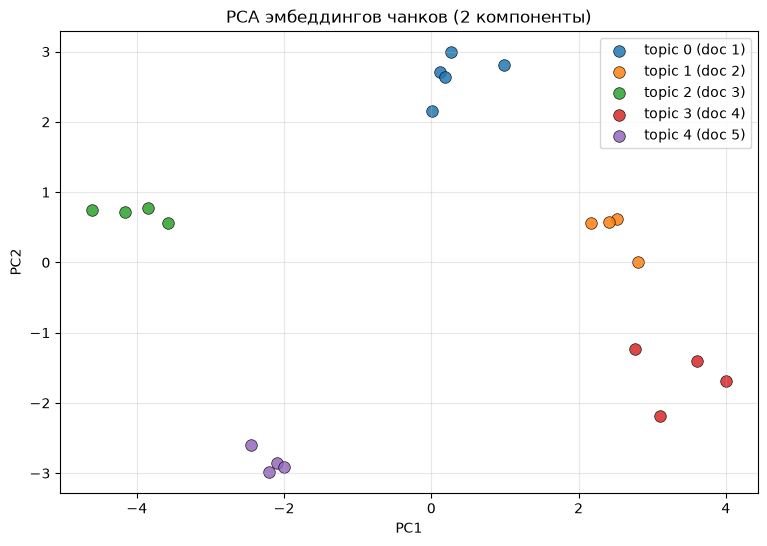

Объяснённая доля дисперсии: PC1 = 0.546 , PC2 = 0.285 , суммарно = 0.831


In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(9, 6))
for t in sorted(chunks['topic'].unique()):
    mask = chunks['topic'] == t
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                label=f'topic {t} (doc {t + 1})', alpha=0.85, s=70,
                edgecolors='black', linewidths=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA эмбеддингов чанков (2 компоненты)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('Объяснённая доля дисперсии: PC1 =', round(pca.explained_variance_ratio_[0], 3),
      ', PC2 =', round(pca.explained_variance_ratio_[1], 3),
      ', суммарно =', round(pca.explained_variance_ratio_.sum(), 3))


### Вывод по заданию 7.2

На плоскости PCA видны пять хорошо разделённых кластеров, соответствующих пяти темам (doc_id 1–5). Две первые главные компоненты объясняют суммарно 0.831 дисперсии (PC1 = 0.546, PC2 = 0.285). Это ожидаемо: эмбеддинги сгенерированы как центр документа + шум, поэтому чанки одного документа лежат плотно вокруг своего центра, а сами центры разнесены в пространстве. Кластеры совпадают с темами — это подтверждает, что поиск по косинусу находит чанки ближайшего по смыслу документа (для запросов doc_id=1 это doc_id=2 — ближайший по центру).
